# Лабораторная работа 3. Первичный анализ данных
## Учебная задача. Предсказание ухода клиента

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [3]:
data = pd.read_csv('datasets/telecom_churn/telecom_churn.csv')
data.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   3333 non-null   object 
 1   Account length          3333 non-null   int64  
 2   Area code               3333 non-null   int64  
 3   International plan      3333 non-null   object 
 4   Voice mail plan         3333 non-null   object 
 5   Number vmail messages   3333 non-null   int64  
 6   Total day minutes       3333 non-null   float64
 7   Total day calls         3333 non-null   int64  
 8   Total day charge        3333 non-null   float64
 9   Total eve minutes       3333 non-null   float64
 10  Total eve calls         3333 non-null   int64  
 11  Total eve charge        3333 non-null   float64
 12  Total night minutes     3333 non-null   float64
 13  Total night calls       3333 non-null   int64  
 14  Total night charge      3333 non-null   

### Визуализация количественных признаков

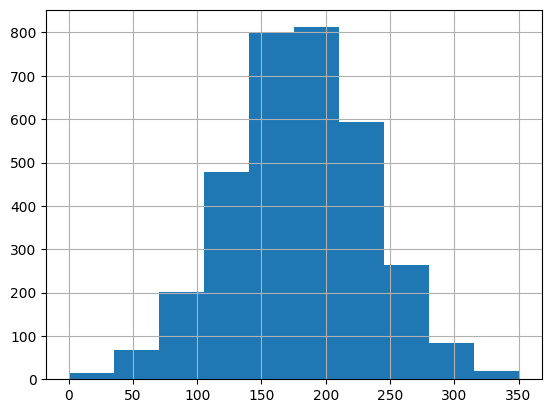

In [5]:
data['Total day minutes'].hist()
plt.show()

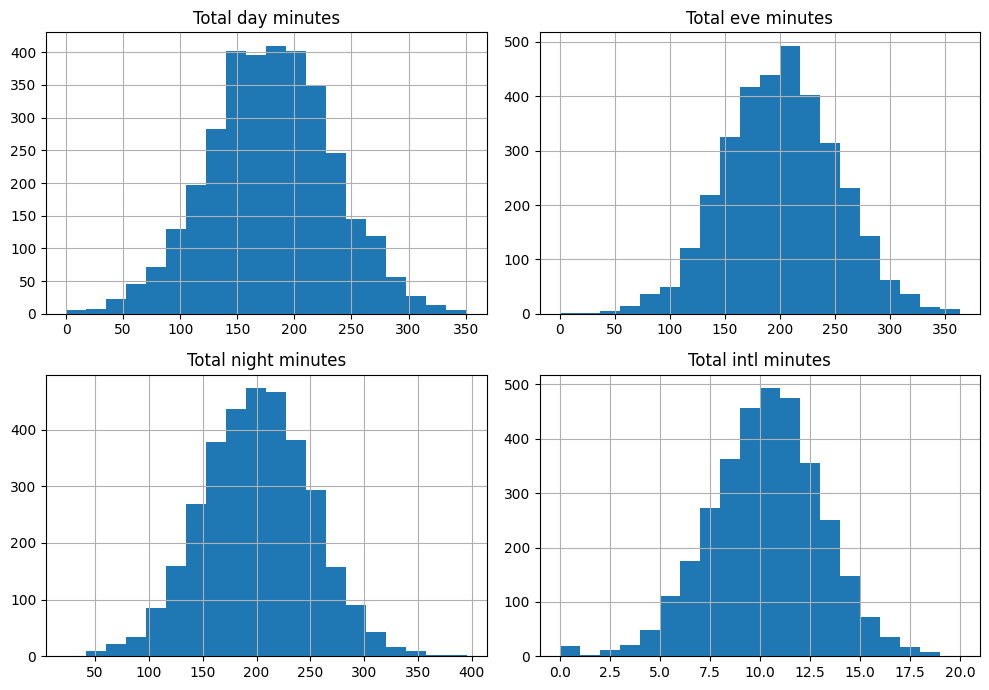

In [6]:
minutes = ['Total day minutes', 'Total eve minutes',
           'Total night minutes', 'Total intl minutes']
df[minutes].hist(figsize=(10, 7), bins=20)
plt.tight_layout()
plt.show()

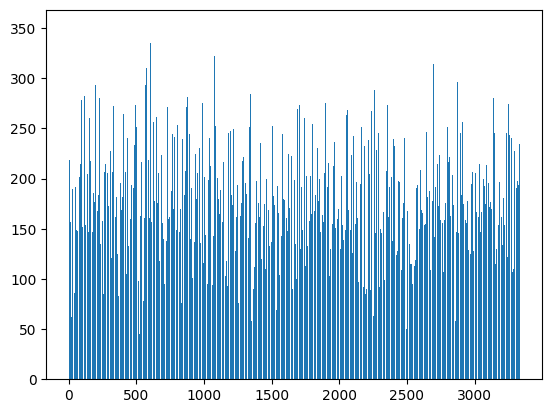

In [7]:
plt.bar(data.index, data['Total day minutes'])
plt.show()

<BarContainer object of 1667 artists>

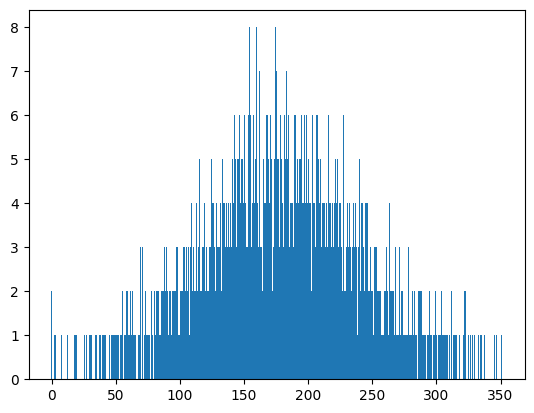

In [8]:
hist = data['Total day minutes'].value_counts()
plt.bar(hist.index, hist)

<Axes: ylabel='Total day minutes'>

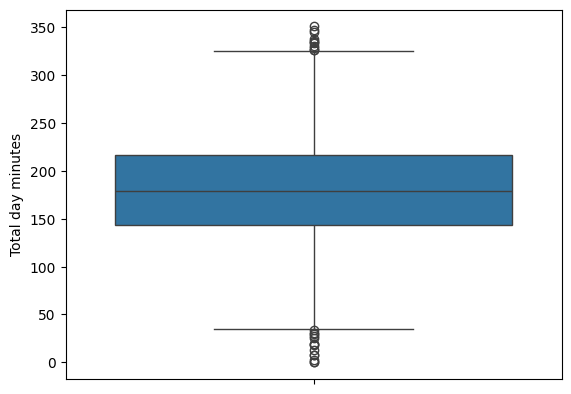

In [10]:
sns.boxplot(data['Total day minutes'])

C:\Users\User\AppData\Local\Temp\ipykernel_5884\3480029231.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y='State',


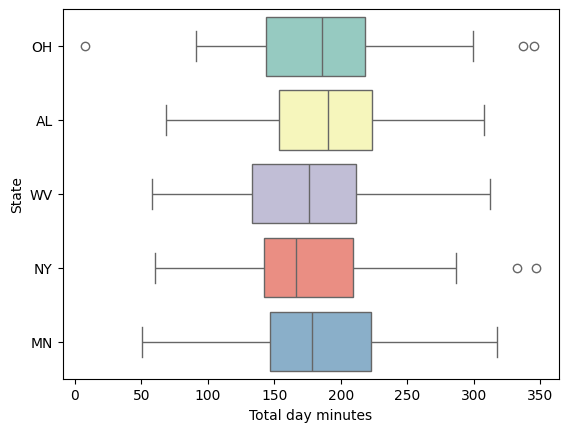

In [12]:
top_data = data[['State', 'Total day minutes']]
top_data = top_data.groupby('State').sum()
top_data = top_data.sort_values('Total day minutes', ascending=False)
top_data = top_data[:5].index.values
sns.boxplot(y='State',
           x='Total day minutes',
           data=data[data.State.isin(top_data)], palette='Set3');

### Категориальные признаки

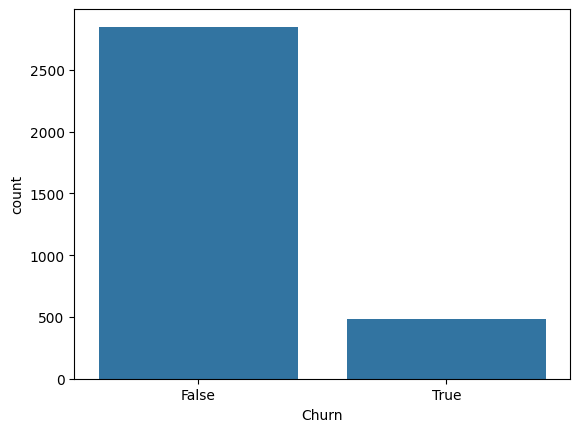

In [16]:
sns.countplot(x='Churn', data=data)
plt.show()

<Axes: xlabel='count', ylabel='State'>

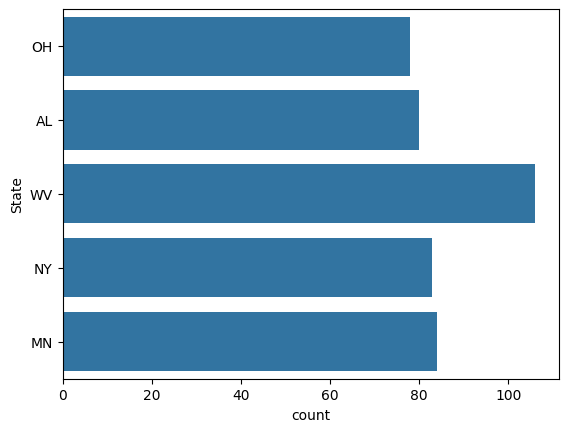

In [17]:
sns.countplot(data[data['State'].isin(data['State'].\
            value_counts().head(5).index)]['State'])

### Соотношения признаков

In [20]:
feats = [f for f in data.columns if 'charge' in f]
feats

['Total day charge',
 'Total eve charge',
 'Total night charge',
 'Total intl charge']

array([[<Axes: title={'center': 'Total day charge'}>,
        <Axes: title={'center': 'Total eve charge'}>],
       [<Axes: title={'center': 'Total night charge'}>,
        <Axes: title={'center': 'Total intl charge'}>]], dtype=object)

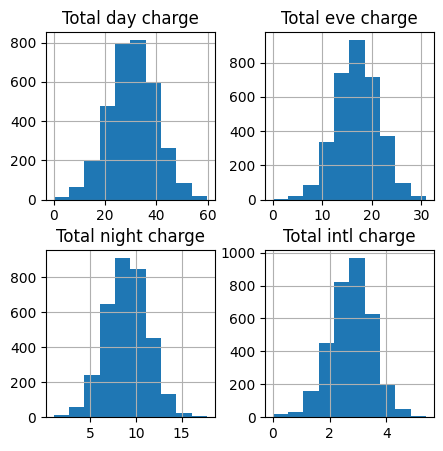

In [21]:
data[feats].hist(figsize=(5, 5))

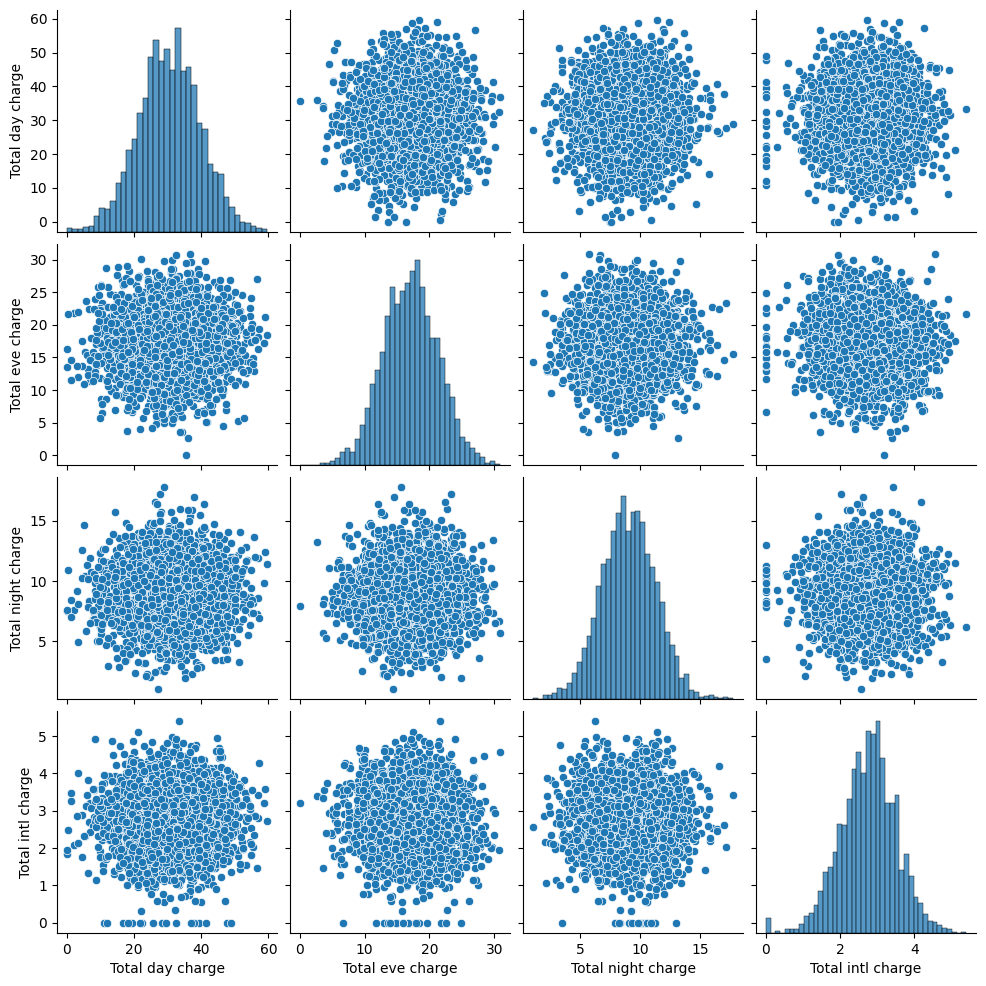

In [22]:
sns.pairplot(data[feats])

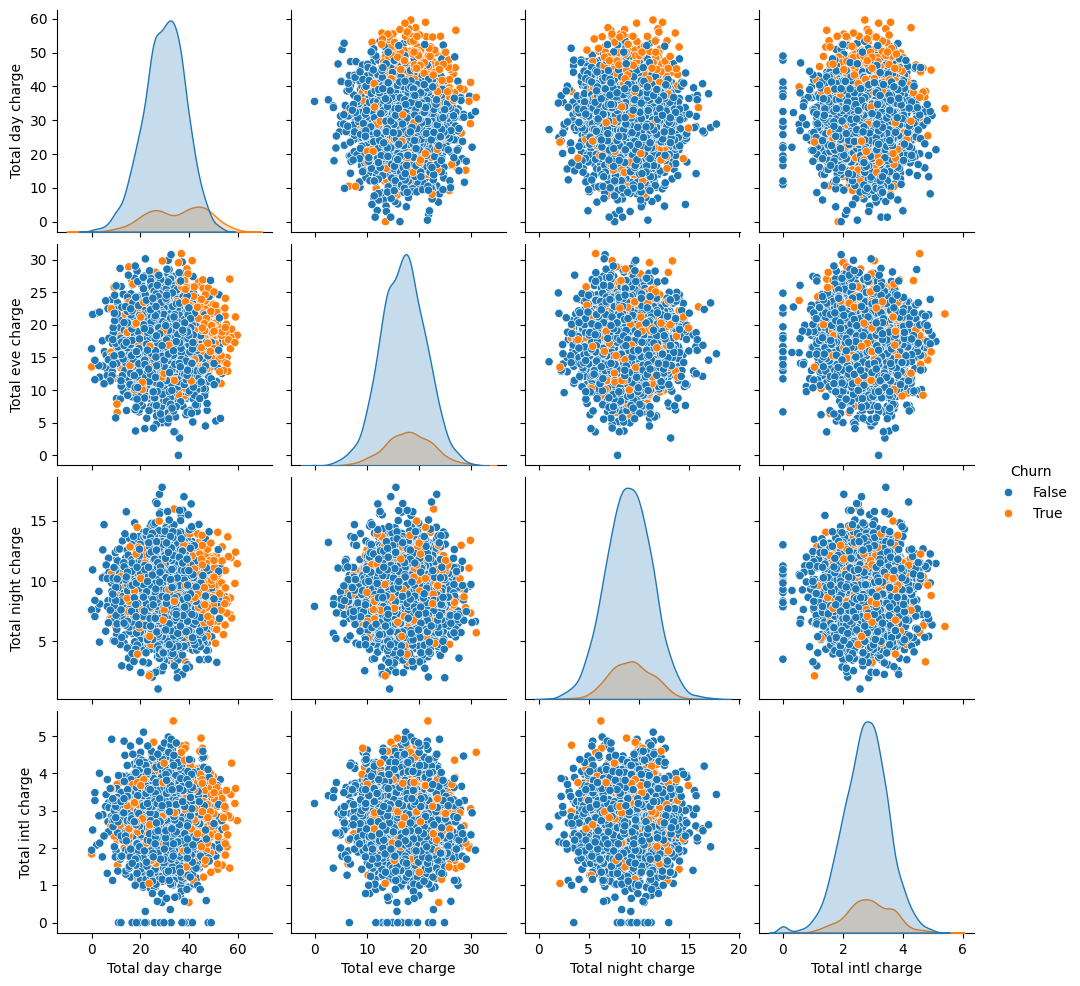

In [23]:
sns.pairplot(data[feats + ['Churn']], hue='Churn')

Text(0.5, 1.0, 'Распределение по 2 признакам')

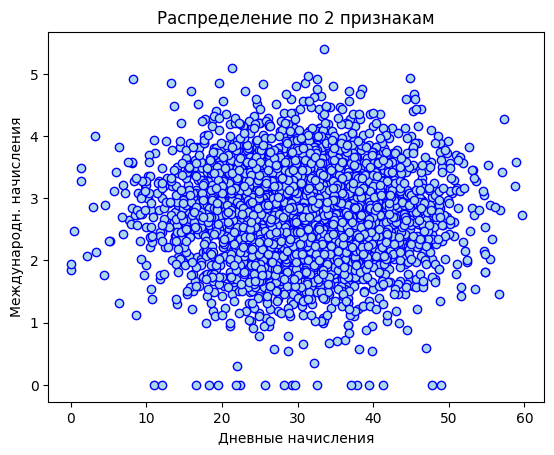

In [24]:
plt.scatter(data['Total day charge'],
           data['Total intl charge'],
           color='lightblue', edgecolor='blue')
plt.xlabel('Дневные начисления')
plt.ylabel('Международн. начисления')
plt.title('Распределение по 2 признакам')

Text(0, 0.5, 'Международн. начисления')

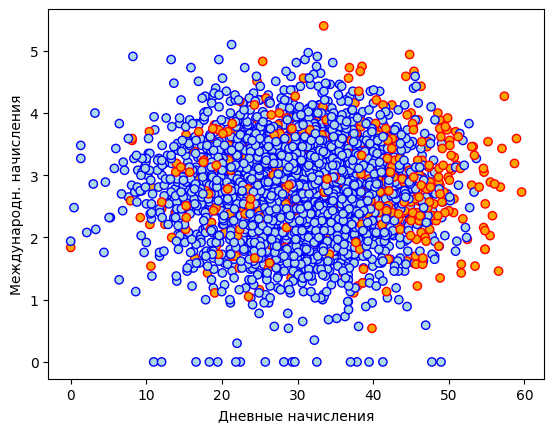

In [26]:
c = data['Churn'].map({False: 'lightblue', True: 'orange'})
edge_c = data['Churn'].map({False: 'blue', True: 'red'})
plt.scatter(data['Total day charge'],
           data['Total intl charge'],
           color=c, edgecolor=edge_c)
plt.xlabel('Дневные начисления')
plt.ylabel('Международн. начисления')

<Axes: >

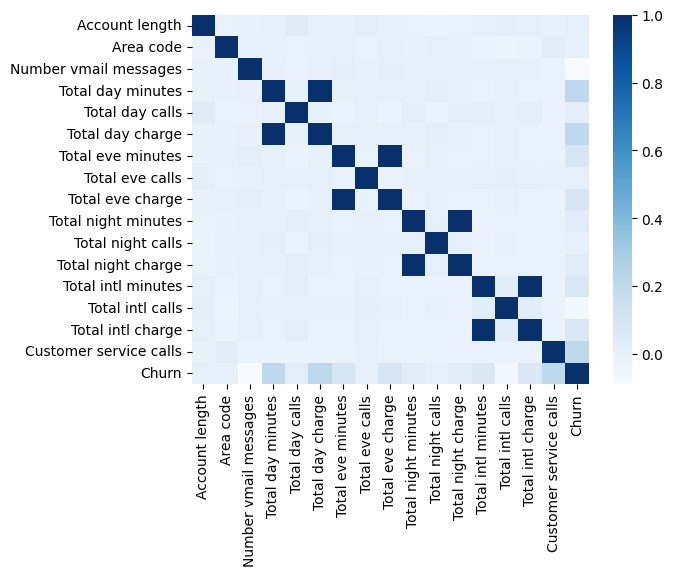

In [28]:
corr = df.corr(numeric_only=True)
sns.heatmap(corr, cmap=plt.cm.Blues)

# Индивидуальное задание. Набор данных Games

In [39]:
games = pd.read_csv('datasets/games/games.csv')
games.head()

,Unnamed: 0,Title,Release Date,Team,Rating,Times Listed,Number of Reviews,Genres,Summary,Reviews,Plays,Playing,Backlogs,Wishlist
0,0,Elden Ring,"Feb 25, 2022","['Bandai Namco Entertainment', 'FromSoftware']",4.5,3.9K,3.9K,"['Adventure', 'RPG']","Elden Ring is a fantasy, action and open world...","[""The first playthrough of elden ring is one o...",17K,3.8K,4.6K,4.8K
1,1,Hades,"Dec 10, 2019",['Supergiant Games'],4.3,2.9K,2.9K,"['Adventure', 'Brawler', 'Indie', 'RPG']",A rogue-lite hack and slash dungeon crawler in...,['convinced this is a roguelike for people who...,21K,3.2K,6.3K,3.6K
2,2,The Legend of Zelda: Breath of the Wild,"Mar 03, 2017","['Nintendo', 'Nintendo EPD Production Group No...",4.4,4.3K,4.3K,"['Adventure', 'RPG']",The Legend of Zelda: Breath of the Wild is the...,['This game is the game (that is not CS:GO) th...,30K,2.5K,5K,2.6K
3,3,Undertale,"Sep 15, 2015","['tobyfox', '8-4']",4.2,3.5K,3.5K,"['Adventure', 'Indie', 'RPG', 'Turn Based Stra...","A small child falls into the Underground, wher...",['soundtrack is tied for #1 with nier automata...,28K,679,4.9K,1.8K
4,4,Hollow Knight,"Feb 24, 2017",['Team Cherry'],4.4,3K,3K,"['Adventure', 'Indie', 'Platform']",A 2D metroidvania with an emphasis on close co...,"[""this games worldbuilding is incredible, with...",21K,2.4K,8.3K,2.3K


In [40]:
games.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1512 entries, 0 to 1511
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         1512 non-null   int64  
 1   Title              1512 non-null   object 
 2   Release Date       1512 non-null   object 
 3   Team               1511 non-null   object 
 4   Rating             1499 non-null   float64
 5   Times Listed       1512 non-null   object 
 6   Number of Reviews  1512 non-null   object 
 7   Genres             1512 non-null   object 
 8   Summary            1511 non-null   object 
 9   Reviews            1512 non-null   object 
 10  Plays              1512 non-null   object 
 11  Playing            1512 non-null   object 
 12  Backlogs           1512 non-null   object 
 13  Wishlist           1512 non-null   object 
dtypes: float64(1), int64(1), object(12)
memory usage: 165.5+ KB


In [30]:
import ast

def to_number(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip().replace(',', '')
    if text.endswith('K'):
        return float(text[:-1]) * 1_000
    if text.endswith('M'):
        return float(text[:-1]) * 1_000_000
    return float(text)

for column in ['Times Listed', 'Number of Reviews',
               'Plays', 'Playing', 'Backlogs', 'Wishlist']:
    games[column] = games[column].map(to_number)

games['Rating'] = pd.to_numeric(games['Rating'], errors='coerce')
games['Release year'] = pd.to_datetime(
    games['Release Date'], format='%b %d, %Y', errors='coerce').dt.year
games['Genres'] = games['Genres'].map(ast.literal_eval)
games['Number of Genres'] = games['Genres'].str.len()

print(games[['Rating', 'Plays', 'Backlogs', 'Wishlist', 'Number of Genres']].describe().round(2))
print('\nПропуски:')
print(games[['Rating', 'Release year']].isna().sum())
print('\nTimes Listed и Number of Reviews совпадают:',
      (games['Times Listed'] == games['Number of Reviews']).all())

        Rating     Plays  Backlogs  Wishlist  Number of Genres
count  1499.00   1512.00   1512.00   1512.00           1512.00
mean      3.72   6253.58   1452.58    780.54              2.41
std       0.53   5894.98   1341.97    801.25              1.07
min       0.70      0.00      1.00      2.00              0.00
25%       3.40   1800.00    461.75    212.00              2.00
50%       3.80   4200.00   1000.00    496.00              2.00
75%       4.10   9100.00   2100.00   1100.00              3.00
max       4.80  33000.00   8300.00   5400.00              7.00

Пропуски:
Rating          13
Release year     3
dtype: int64

Times Listed и Number of Reviews совпадают: True


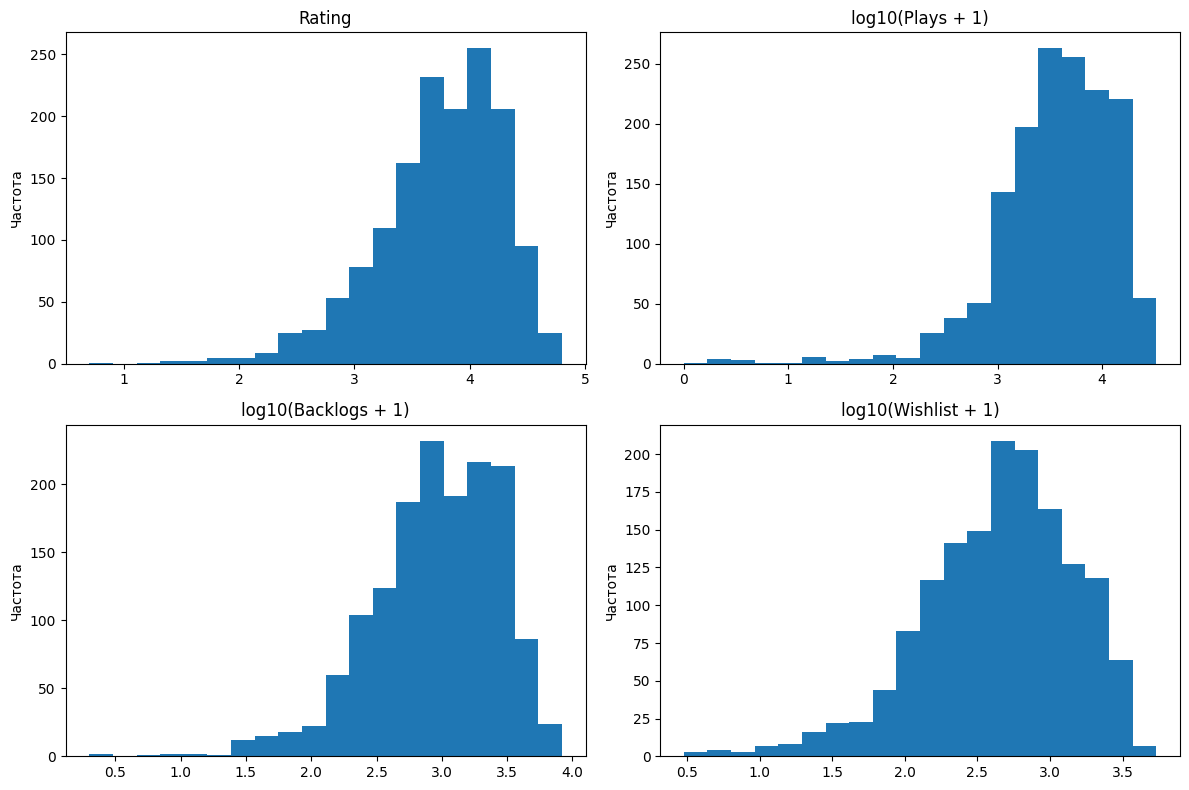

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].hist(games['Rating'].dropna(), bins=20)
axes[0, 0].set_title('Rating')
axes[0, 1].hist(np.log10(games['Plays'] + 1), bins=20)
axes[0, 1].set_title('log10(Plays + 1)')
axes[1, 0].hist(np.log10(games['Backlogs'] + 1), bins=20)
axes[1, 0].set_title('log10(Backlogs + 1)')
axes[1, 1].hist(np.log10(games['Wishlist'] + 1), bins=20)
axes[1, 1].set_title('log10(Wishlist + 1)')
for ax in axes.ravel():
    ax.set_ylabel('Частота')
plt.tight_layout()
plt.show()

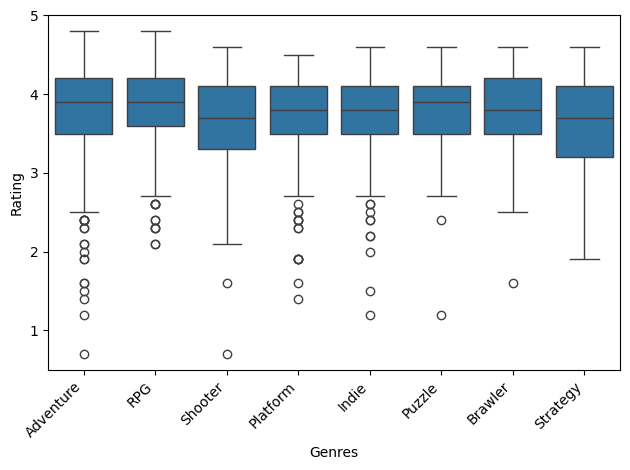

In [32]:
genres = games.explode('Genres').dropna(subset=['Genres']).reset_index(drop=True)
top_genres = genres['Genres'].value_counts().head(8).index

sns.boxplot(x='Genres', y='Rating', data=genres[genres['Genres'].isin(top_genres)],
            order=top_genres)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

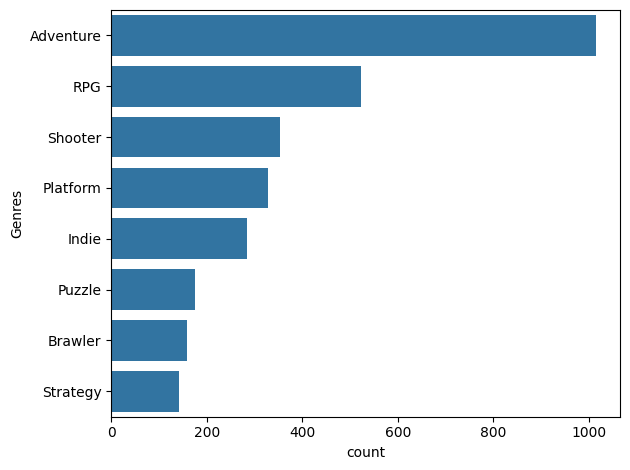

In [33]:
sns.countplot(y='Genres', data=genres, order=top_genres)
plt.tight_layout()
plt.show()

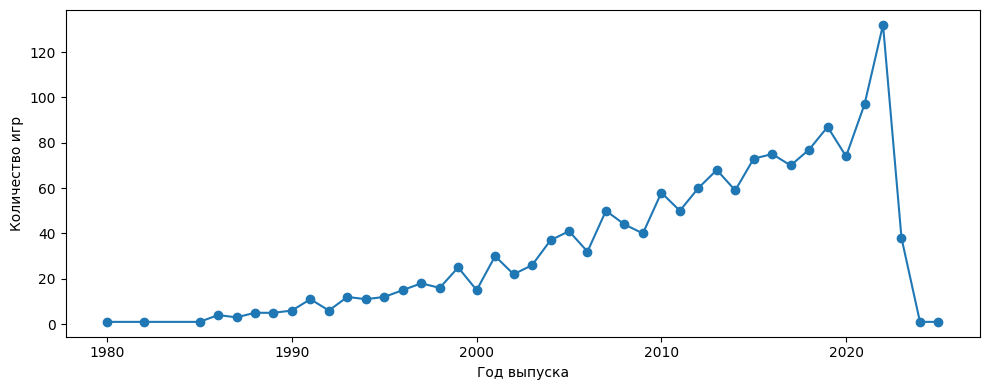

In [34]:
year_counts = games['Release year'].value_counts().sort_index()
plt.figure(figsize=(10, 4))
plt.plot(year_counts.index, year_counts.values, marker='o')
plt.xlabel('Год выпуска')
plt.ylabel('Количество игр')
plt.tight_layout()
plt.show()

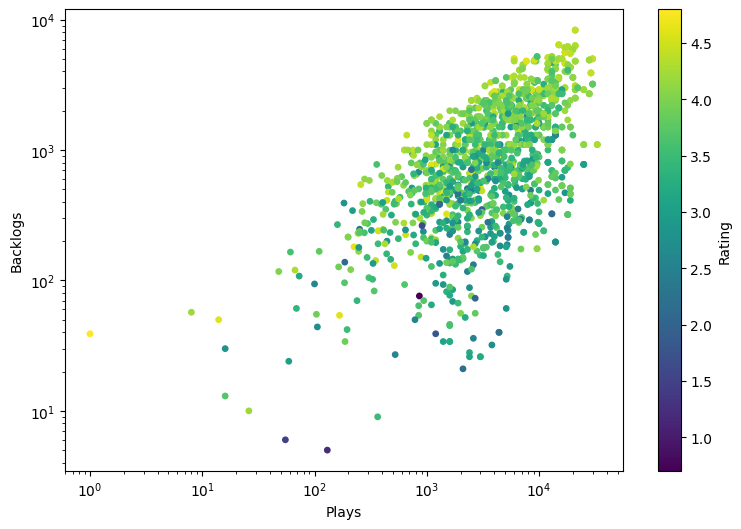

In [35]:
scatter_data = games.dropna(subset=['Rating'])
plt.figure(figsize=(9, 6))
plt.scatter(scatter_data['Plays'], scatter_data['Backlogs'],
            c=scatter_data['Rating'], cmap='viridis', s=15)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Plays')
plt.ylabel('Backlogs')
plt.colorbar(label='Rating')
plt.show()

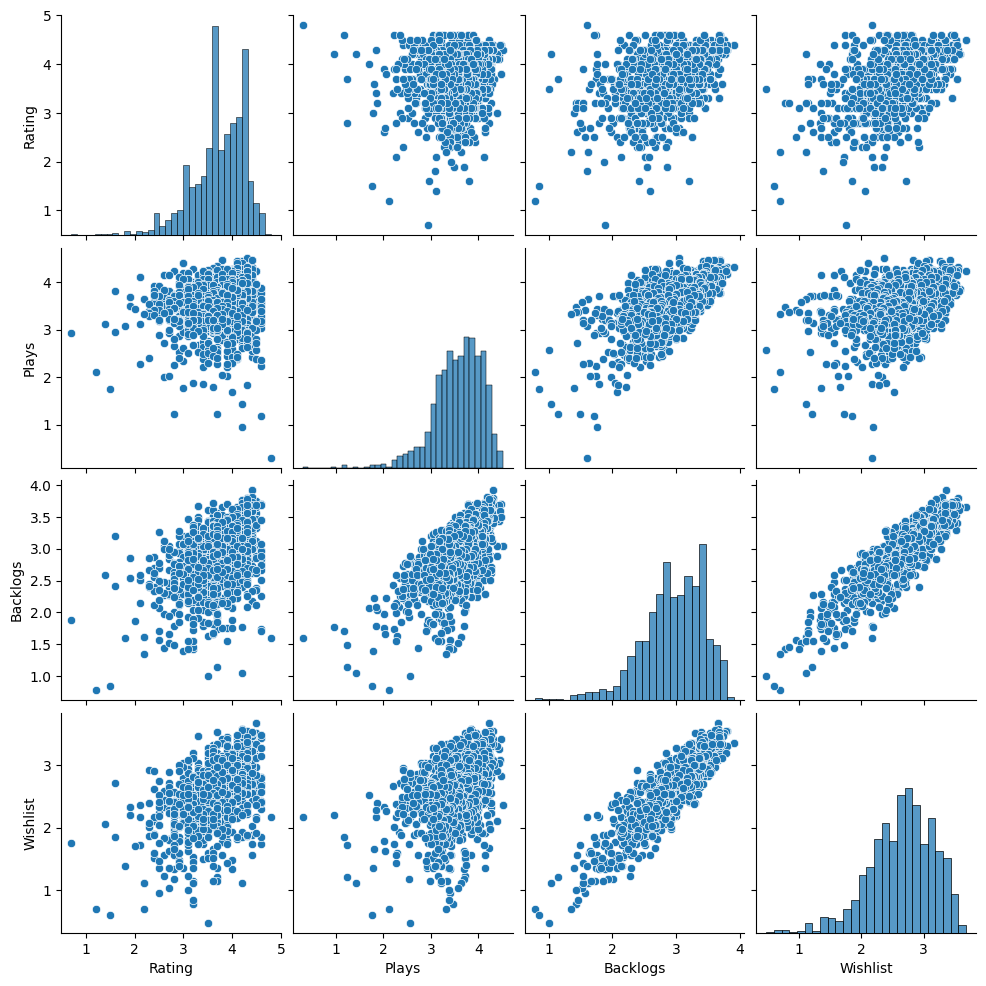

In [36]:
log_games = games[['Rating', 'Plays', 'Backlogs', 'Wishlist']].copy()
for column in ['Plays', 'Backlogs', 'Wishlist']:
    log_games[column] = np.log10(log_games[column] + 1)

sns.pairplot(log_games.dropna())
plt.show()

                  Rating  Number of Genres  Plays  Backlogs  Wishlist  \
Rating              1.00              0.07   0.20      0.44      0.46   
Number of Genres    0.07              1.00  -0.02      0.11      0.09   
Plays               0.20             -0.02   1.00      0.60      0.35   
Backlogs            0.44              0.11   0.60      1.00      0.79   
Wishlist            0.46              0.09   0.35      0.79      1.00   
Release year        0.01              0.22  -0.06      0.13      0.32   

                  Release year  
Rating                    0.01  
Number of Genres          0.22  
Plays                    -0.06  
Backlogs                  0.13  
Wishlist                  0.32  
Release year              1.00  


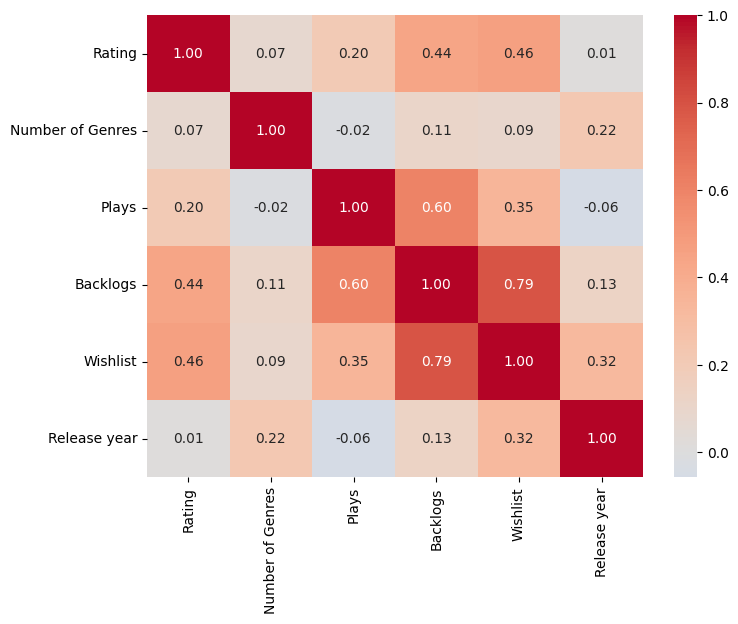

In [37]:
corr = games[['Rating', 'Number of Genres', 'Plays',
                     'Backlogs', 'Wishlist', 'Release year']].corr()
print(corr.round(2))

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.show()